# Proyecto - Asistente de IA para aerolínea

Ahora vamos a reunir lo que hemos aprendido para crear un asistente de IA de atención al cliente para una aerolínea

In [1]:
# imports

import os
import json
from dotenv import load_dotenv
from openai import OpenAI
import gradio as gr
import sqlite3

c:\Users\ricky\ml-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Inicialización

load_dotenv(override=True)

google_api_key = os.getenv('GOOGLE_API_KEY')
if google_api_key:
    print(f"La clave de API de Google existe y comienza con {google_api_key[:8]}")
else:
    print("La clave de API de Google no está configurada")

MODEL = "gemini-3.1-flash-lite"
gemini = OpenAI(api_key=google_api_key, base_url="https://generativelanguage.googleapis.com/v1beta/openai/")

DB = "prices.db"

La clave de API de Google existe y comienza con AQ.Ab8RN


In [3]:
system_message = """
Eres un asistente útil para una aerolínea llamada FlightAI.
Da respuestas breves y amables, de no más de 1 oración.
Sé siempre preciso. Si no sabes la respuesta, dilo.
"""

In [4]:
def get_ticket_price(city):
    print(f"LLAMADA A LA HERRAMIENTA DE BASE DE DATOS: Obteniendo precio para {city}", flush=True)
    with sqlite3.connect(DB) as conn:
        cursor = conn.cursor()
        cursor.execute('SELECT price FROM prices WHERE city = ?', (city.lower(),))
        result = cursor.fetchone()
        return f"El precio del boleto a {city} es ${result[0]}" if result else "No hay datos de precio disponibles para esta ciudad"

In [5]:
get_ticket_price("Paris")

LLAMADA A LA HERRAMIENTA DE BASE DE DATOS: Obteniendo precio para Paris


'El precio del boleto a Paris es $899.0'

In [6]:
price_function = {
    "name": "get_ticket_price",
    "description": "Obtiene el precio de un boleto de ida y vuelta a la ciudad de destino.",
    "parameters": {
        "type": "object",
        "properties": {
            "destination_city": {
                "type": "string",
                "description": "La ciudad a la que el cliente quiere viajar",
            },
        },
        "required": ["destination_city"],
        "additionalProperties": False
    }
}
tools = [{"type": "function", "function": price_function}]
tools

[{'type': 'function',
  'function': {'name': 'get_ticket_price',
   'description': 'Obtiene el precio de un boleto de ida y vuelta a la ciudad de destino.',
   'parameters': {'type': 'object',
    'properties': {'destination_city': {'type': 'string',
      'description': 'La ciudad a la que el cliente quiere viajar'}},
    'required': ['destination_city'],
    'additionalProperties': False}}}]

In [7]:
def chat(message, history):
    history = [{"role": h["role"], "content": h["content"]} for h in history]
    messages = [{"role": "system", "content": system_message}] + history + [{"role": "user", "content": message}]
    response = gemini.chat.completions.create(model=MODEL, messages=messages)
    return response.choices[0].message.content

gr.ChatInterface(fn=chat, type="messages").launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [8]:
def chat(message, history):
    history = [{"role":h["role"], "content":h["content"]} for h in history]
    messages = [{"role": "system", "content": system_message}] + history + [{"role": "user", "content": message}]
    response = gemini.chat.completions.create(model=MODEL, messages=messages, tools=tools)

    while response.choices[0].finish_reason=="tool_calls":
        message = response.choices[0].message
        responses = handle_tool_calls(message)
        messages.append(message)
        messages.extend(responses)
        response = gemini.chat.completions.create(model=MODEL, messages=messages, tools=tools)
    
    return response.choices[0].message.content

In [9]:
def handle_tool_calls(message):
    responses = []
    for tool_call in message.tool_calls:
        if tool_call.function.name == "get_ticket_price":
            arguments = json.loads(tool_call.function.arguments)
            city = arguments.get('destination_city')
            price_details = get_ticket_price(city)
            responses.append({
                "role": "tool",
                "content": price_details,
                "tool_call_id": tool_call.id
            })
    return responses

In [10]:
gr.ChatInterface(fn=chat, type="messages").launch()

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


## Un poco más sobre lo que hace Gradio:

1. Gradio construye una aplicación de frontend en Svelte a partir de nuestra descripción en Python de la interfaz
2. Gradio inicia un servidor basado en el framework web Starlette, que escucha en un puerto libre y sirve esta aplicación Svelte
3. Gradio crea rutas de backend para nuestros callbacks, como chat(), que llaman a nuestras funciones

Y, por supuesto, al generar la aplicación de frontend, Gradio se asegura de que el botón de enviar llame a la ruta de backend correcta.

¡Eso es todo!

Es simple, y el resultado se siente mágico.

# ¡Vamos a lo multimodal!

Podemos generar imágenes localmente con Stable Diffusion 1.5. Es gratis, pero usa la GPU de tu equipo.

Vamos a poner esto en una función llamada artist.

### Aviso: la primera carga del modelo tarda unos segundos y cada imagen unos 20 segundos en una GTX 1660 Ti. Las imágenes son de 512×512.

In [11]:
# Algunos imports para manejar imágenes

import base64
from io import BytesIO
from PIL import Image

In [12]:
# Generación local con Stable Diffusion 1.5 (gratis, usa tu GPU)
# Se usa fp32: en fp16 la GTX 1660 Ti genera imágenes completamente negras
import torch
from diffusers import StableDiffusionPipeline

sd_pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    torch_dtype=torch.float32,
    safety_checker=None,   # desactivado para ahorrar descarga y memoria en esta práctica
    feature_extractor=None,
)
sd_pipe.enable_attention_slicing()
sd_pipe.to("cuda")

def artist(city):
    image = sd_pipe(
        f"An image representing a vacation in {city}, showing tourist spots and everything unique about {city}, in a vibrant pop-art style",
        height=512,
        width=512,
        num_inference_steps=25,
        guidance_scale=7.5,
    ).images[0]
    return image

W1016 00:20:29.103000 13616 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
c:\Users\ricky\ml-env\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading pipeline components...: 100%|██████████| 5/5 [00:02<00:00,  1.94it/s]
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases t

100%|██████████| 25/25 [00:16<00:00,  1.53it/s]


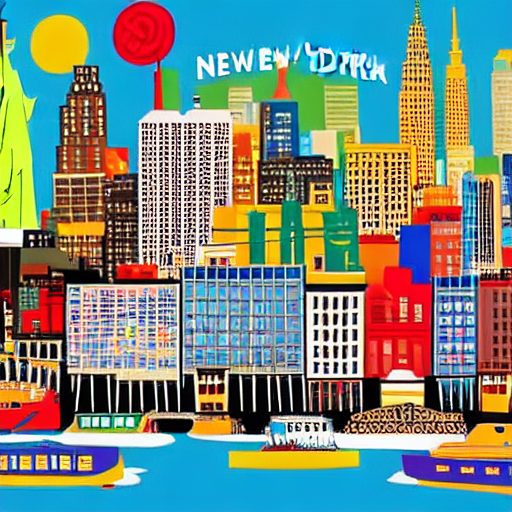

In [13]:
image = artist("New York City")
display(image)

In [ ]:
# La compatibilidad con OpenAI no incluye TTS, así que usamos el SDK nativo de Google
from google import genai
from google.genai import types
import numpy as np

gemini_audio = genai.Client(api_key=google_api_key)

def talker(message):
    response = gemini_audio.models.generate_content(
        model="gemini-3.8-flash-tts",
        contents=message,
        config=types.GenerateContentConfig(
            response_modalities=["AUDIO"],
            speech_config=types.SpeechConfig(
                voice_config=types.VoiceConfig(
                    prebuilt_voice_config=types.PrebuiltVoiceConfig(voice_name="Kore")  # Prueba también con Puck, Zephyr o Charon
                )
            ),
        ),
    )
    pcm = response.candidates[0].content.parts[0].inline_data.data
    # El audio llega como PCM crudo: 24 kHz, 16 bits, mono. Gradio acepta (frecuencia, muestras)
    return 24000, np.frombuffer(pcm, dtype=np.int16)

## Juntemos todo:

1. Un asistente de IA multimodal con generación de imágenes y audio
2. Llamadas a herramientas con consulta a una base de datos
3. Un paso hacia un flujo de trabajo agéntico

In [ ]:
def chat(history):
    history = [{"role":h["role"], "content":h["content"]} for h in history]
    messages = [{"role": "system", "content": system_message}] + history
    response = gemini.chat.completions.create(model=MODEL, messages=messages, tools=tools)
    cities = []
    image = None

    while response.choices[0].finish_reason=="tool_calls":
        message = response.choices[0].message
        responses, cities = handle_tool_calls_and_return_cities(message)
        messages.append(message)
        messages.extend(responses)
        response = gemini.chat.completions.create(model=MODEL, messages=messages, tools=tools)

    reply = response.choices[0].message.content
    history += [{"role":"assistant", "content":reply}]

    voice = talker(reply)

    if cities:
        image = artist(cities[0])
    
    return history, voice, image

In [ ]:
def handle_tool_calls_and_return_cities(message):
    responses = []
    cities = []
    for tool_call in message.tool_calls:
        if tool_call.function.name == "get_ticket_price":
            arguments = json.loads(tool_call.function.arguments)
            city = arguments.get('destination_city')
            cities.append(city)
            price_details = get_ticket_price(city)
            responses.append({
                "role": "tool",
                "content": price_details,
                "tool_call_id": tool_call.id
            })
    return responses, cities

## Los 3 tipos de interfaz de Gradio

`gr.Interface` sirve para interfaces estándar y sencillas

`gr.ChatInterface` sirve para interfaces de chatbot estándar

`gr.Blocks` sirve para interfaces personalizadas donde controlas los componentes y los callbacks

In [ ]:
# Callbacks (junto con la función chat() de arriba)

def put_message_in_chatbot(message, history):
        return "", history + [{"role":"user", "content":message}]

# Definición de la interfaz

with gr.Blocks() as ui:
    with gr.Row():
        chatbot = gr.Chatbot(height=500, type="messages")
        image_output = gr.Image(height=500, interactive=False)
    with gr.Row():
        audio_output = gr.Audio(autoplay=True)
    with gr.Row():
        message = gr.Textbox(label="Chatea con nuestro asistente de IA:")

# Conectando eventos a callbacks

    message.submit(put_message_in_chatbot, inputs=[message, chatbot], outputs=[message, chatbot]).then(
        chat, inputs=chatbot, outputs=[chatbot, audio_output, image_output]
    )

ui.launch(inbrowser=True, auth=("ed", "bananas"))

# Ejercicios y aplicaciones de negocio

Añade más herramientas, por ejemplo para simular la reserva real de un vuelo. Un estudiante ya lo hizo y dejó su ejemplo en la carpeta de contribuciones de la comunidad.

Siguiente paso: aplica esto a tu negocio. Crea un asistente de IA multimodal con herramientas que puedan realizar una actividad de tu trabajo. ¿Un asistente de atención al cliente? ¿Un asistente para el onboarding de nuevos empleados? ¡Hay muchísimas posibilidades! Además, mira el ejercicio de fin de semana de la semana 2 en el notebook aparte.

<table style="margin: 0; text-align: left;">
    <tr>
        <td style="width: 150px; height: 150px; vertical-align: middle;">
            <img src="../assets/thankyou.jpg" width="150" height="150" style="display: block;" />
        </td>
        <td>
            <h2 style="color:#090;">Una petición especial</h2>
            <span style="color:#090;">
                Mi editor me dice que hace una GRAN diferencia cuando los estudiantes califican este curso en Udemy: es una de las principales formas en que Udemy decide si lo muestra a otras personas. Si puedes tomarte un minuto para calificarlo, te lo agradecería muchísimo. Y, pase lo que pase, escríbeme a ed@edwarddonner.com si puedo ayudarte en algo.
            </span>
        </td>
    </tr>
</table>